<h1 align="center">Module 4 - RAG</h1>
<h3 align="center">AI Engineering</h3>

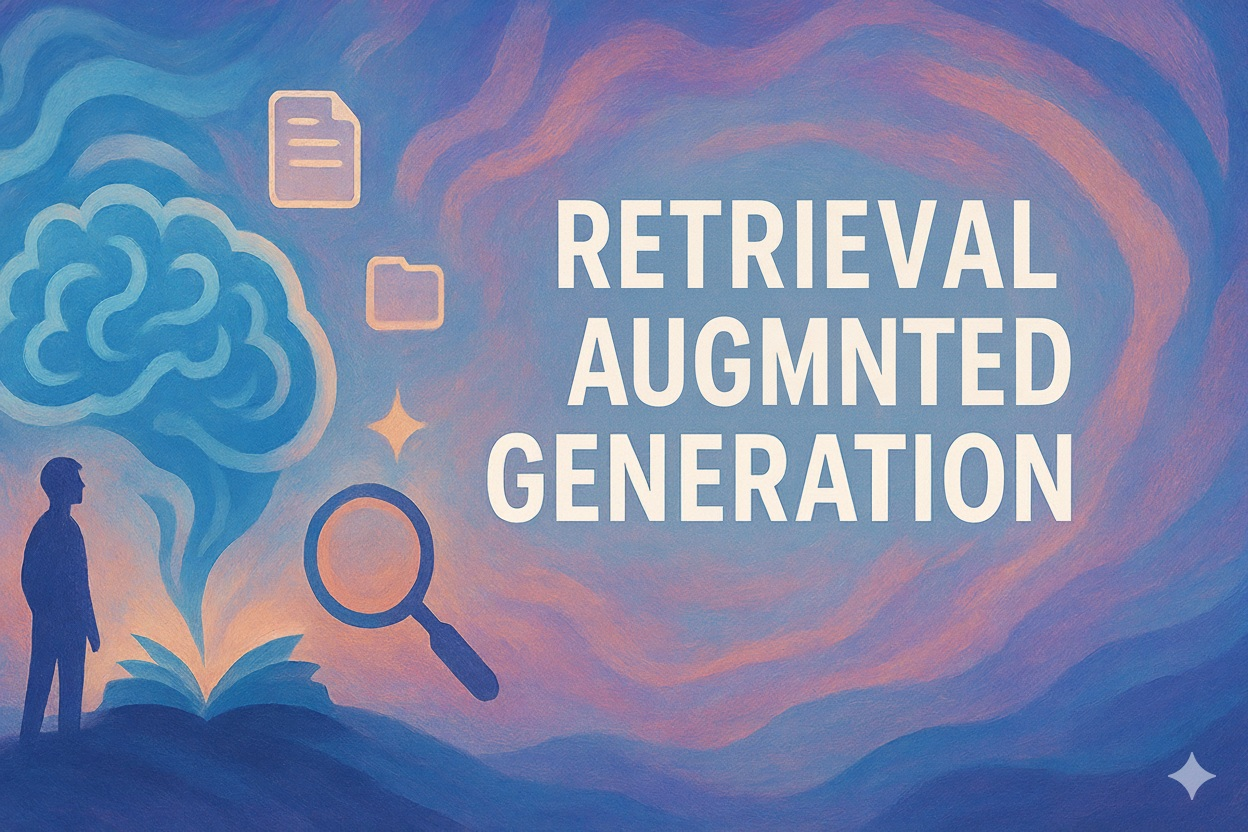

This module focuses on **building and understanding RAG systems**:

- document ingestion and cleanup,
- chunking,
- embeddings and vector stores,
- lexical, semantic, and hybrid retrieval,
- metadata filtering and reranking,
- context construction and grounded prompting,
- practical debugging of RAG failures.

We will **not** go deeply into API wrapping, production deployment, full observability infrastructure, advanced application evaluation, security hardening, or indirect prompt-injection defense here. Those belong to later modules, after you are comfortable building the RAG pipeline itself.

# Section 1 - Introduction

RAG is a technique using which an LLM's knowledge is augmented (expanded) with the help of an external retrieval system that fetches relevant documents or context from some knowledge base at runtime, improving the LLM's answers. RAG is one of the most exciting and useful developments in AI these days and it enjoys wide adaptation across industries.

**RAG as an AI Engineering pattern.** It is more than "retrieval + generation." It is an **application pattern for grounding an LLM in external knowledge at runtime**. The quality of the final answer depends on a chain of engineering decisions, not just on the model.

#### Why use RAG?

* **LLMs are limited to static, pre-trained knowledge.** As of today (end of 2025), LLMs have a clear *knowledge cut-off date*. This means that they have been trained on data up to that cut-off date, making them completely oblivious to more recent data.
* **Fine-tuning is expensive and slow.** It is possible to *fine-tune* an LLM, introducing it to new data. However, *fine-tuning* is resource intensive, expensive and takes time to complete.  
* **RAG allows LLMs to dynamically "look up" current, domain-specific, or proprietary information.** *Fine-tuning* cannot keep-up with most recent data (as the model cannot be fine-tuned in real-time or even close to real-time), so the knowledge gap remains (although a smaller one). RAG can access the most current information whether it's in-house or out there on the internet (via search).

#### Example Use Cases

`1.` ***Enterprise Search & Knowledge Assistants***. Internal tools that allow employees to ask natural language questions and get answers grounded in company documentation, wikis, and manuals.
* **IBM Watsonx Assistant** uses RAG to provide enterprise-grade AI chatbots that can pull from internal documents securely.
* **Glean** uses RAG for semantic enterprise search.

`2.` ***Legal and Regulatory Document Q&A***. Law firms and compliance departments use RAG to answer complex queries using large corpora of regulations, case law, and internal policies.
* **Harvey.ai** uses RAG to help lawyers quickly find precedents and legal context.
* **CaseText** built *CoCounsel*, a legal assistant powered by RAG.

`3.` ***Scientific Research & Literature Review***. Tools that allow researchers to query across mountains of academic papers and synthesize answers.
* **Consensus.app** uses RAG over peer-reviewed research to give evidence-based answers to scientific questions.
* **Iris.ai** helps researchers navigate large research corpora using RAG-enhanced question answering.

`4.` ***Healthcare & Medical Documentation***. Clinical assistants that answer questions using patient data, research papers, or drug databases while staying grounded.
* **Glass Health** uses RAG to assist clinicians with differential diagnoses.
* **Google DeepMind’s Med-PaLM 2** incorporates RAG to answer medical questions with high accuracy.

`5.` ***Customer Support Automation***. AI chatbots that can give accurate responses using support documentation, FAQs, and past tickets.
* **Intercom’s Fin** offers a support bot which uses RAG to answer questions based on product documentation.
* **Zendesk AI** and **Freshworks Freddy AI** integrate RAG-like systems to enhance bot accuracy.

`6.` ***Financial and Investment Research***. Summarizing and answering questions about earnings reports, news, market trends, and regulatory filings.
* **BloombergGPT** and **Thomson Reuters** are building LLMs enhanced by RAG over massive financial datasets.
* **FinRobot** is an open-source effort in this space.

`7.` ***Education & Tutoring***. Personalized tutors that can answer questions based on specific textbooks or lecture materials.
* **Khan Academy’s Khanmigo*** uses RAG to pull context from learning materials and help students.
* **Quizlet** uses AI to create context-aware study materials from textbooks.

`8.` ***Developer Tools & API Documentation Search***. Developers can query API docs, code examples, or Stack Overflow-style Q&A using natural language.
* **Cursor.sh** and **GitHub Copilot** use RAG on codebases and docs to assist developers in-context.
* **OpenAI's own API Assistants** now allow uploading files to enhance retrieval and response generation.

## Core Components of RAG - Overview

The basic workflow of RAG, also referred to as ***pipeline***, is straightforward:

<center>
    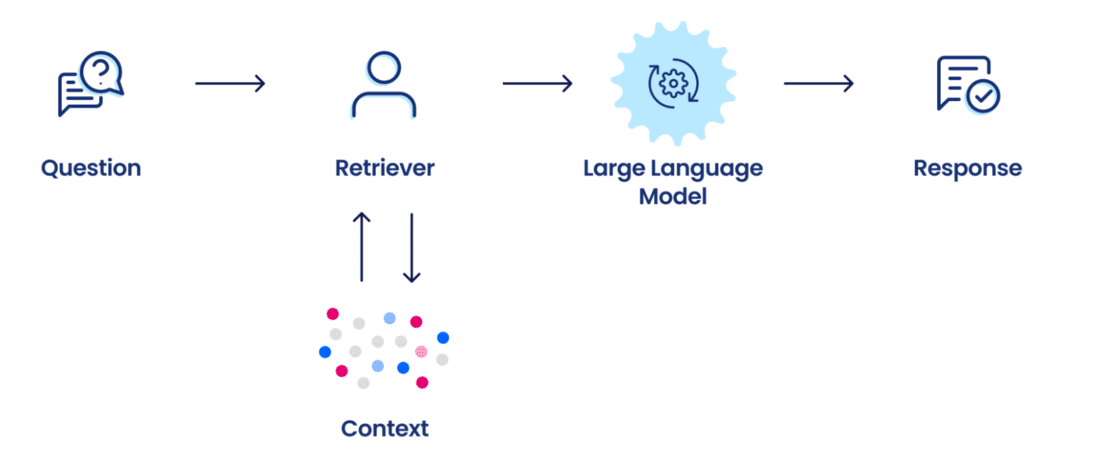
    <h6>
        <a href="https://pub.towardsai.net/rag-explained-key-component-in-large-language-model-llm-e9b8e2083a45">Source: Which is better, retrieval augmentation (RAG) or fine-tuning? Both.</a>
    </h6>
</center>


There are several key concepts behind the workflow. We'll briefly explain them here, and expand on them later. 

#### Retriever
Finds relevant documents from a knowledge base or corpus. This component is responsible for pulling the documents with which to augment the prompt, based on the user's query.

In many cases, a one-stage retrieval is not enough, and the retrieved documents need to be further processed. For example, the documents may be re-ranked using a specially trained LLM for relevance given the query.

There are three main approaches for retrieving the data: *lexical / exact match* (based on tagging and keywords), *semantic* (based on similarity) and *hybrid* which combines the two.
#### Chunking
Split long documents into smaller parts (e.g., 100–500 tokens) so they fit context windows, excluding unneeded information.
#### Embedding
Convert text chunks to dense vectors, preserving the semantics of the chunk. The idea is for chunks revolving around a given subject to have "similar" embeddings. More specifically, the distance between the embeddings has to be smaller, the semantically closer they are to one another.
#### Vector Databases
A vector database stores and indexes the embeddings (and often the chunks themselves) for efficient similarity search.
#### Context Injection
Once relevant documents are retrieved, they need to be introduced to the LLM’s prompt. This is, in practice, *prompt engineering* and has the potential to significantly affect the quality of the results (as is generally the case with constructing the right prompt).
#### Query Reformulation
Improves retrieval quality by converting natural questions into optimized search queries. Sometimes performed using a smaller LLM or a template.

   

> **A zoom into the pipeline looks more like this:**
>
> ```mermaid
> flowchart LR
>    A[Documents] --> B["Ingestion /<br/>cleanup"]
>    B --> C[Chunks]
>    C --> D[Embeddings]
>    D --> E["Vector<br/>store"]
>    E --> F[Retriever]
>    F --> G["Prompt +<br/>context"]
>    G --> H["Answer +<br/>sources"]
> ```


#### Much more...
Naturally, with the popularity and advancement of RAG, many techniques and processes have been developed to answer a wide variety of needs (new ones and refined ones are being introduced). The diagram below provides a hint of what other options are out there:

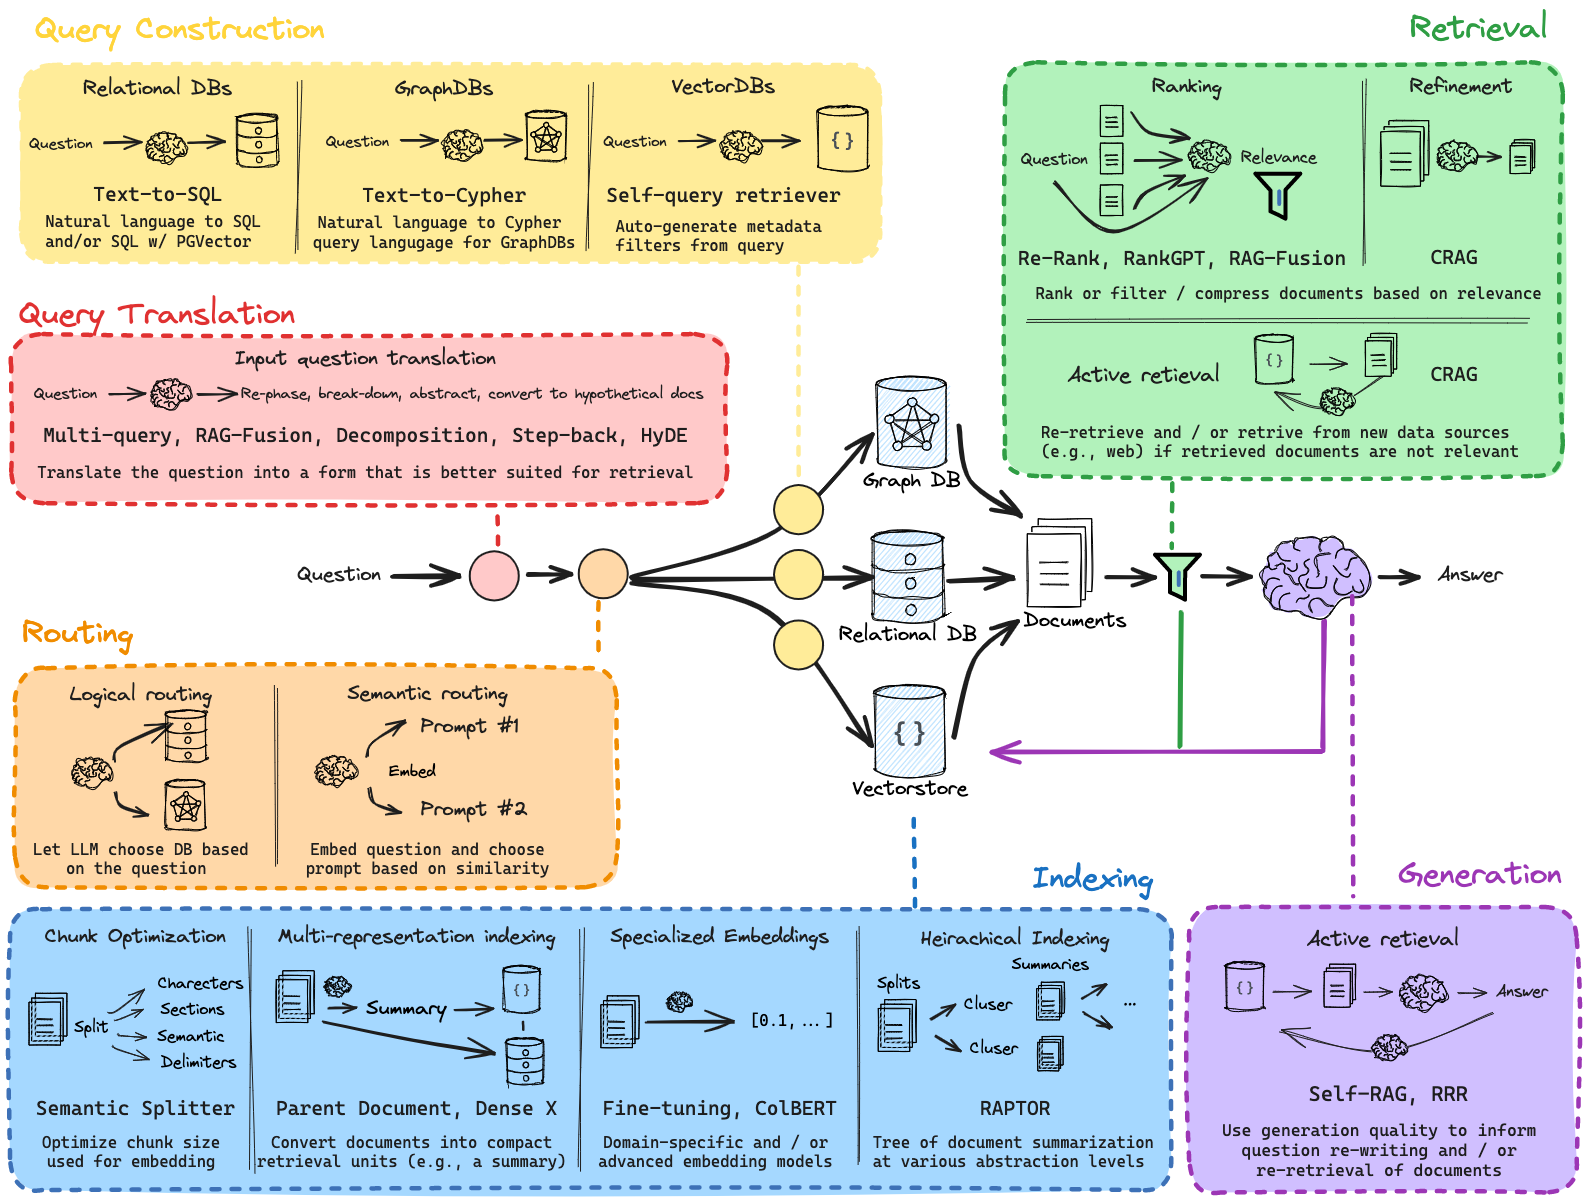

Source: [Understanding Retrieval-Augmented Generation (RAG)](https://medium.com/@kamalrm56workspace/understanding-retrieval-augmented-generation-rag-a-visual-guide-to-the-future-of-ai-powered-1507527c88ce)

## A Word on RAG's Limitations

While RAG is powerful, it's not a silver bullet. There are several limitations and situations where RAG might not be appropriate or might require careful design to be effective.

`1.` ***Garbage In, Garbage Out***. RAG is only as good as the data it retrieves. If your retrieval step pulls irrelevant or outdated content, the generation step will hallucinate or mislead. Poor chunking (we'll see), bad document hygiene, or irrelevant embeddings --> bad results.
<br/><br/>
`2.` ***Lack of Reasoning Across Documents***. Most RAG systems fetch and summarize documents individually, but LLMs struggle to *reason across multiple retrieved contexts*. For instance, comparing pros/cons of two policies from different PDFs can fail if both aren’t presented well together.
<br/><br/>
`3.` ***Context Length Bottlenecks***. Even with longer context windows, the content volume that can feed to the LLM is limited. If relevant information is spread across many large documents, important bits may get cut out. 
> To put things in perspective, Anthropic's Opus 5 offers a 1M tokens context. The Torah is approximately 120K tokens).

`4.` ***Retrieval Quality Tuning is Hard***. Vector similarity (we'll see) doesn't always match human relevance - top retrieved chunks may miss key answers. *Hybrid search* (e.g., semantic + lexical) and *re-ranking* are essential but can add complexity. We'll touch on these later on.
<br/><br/>
`5.` ***Latency & Cost***. RAG systems often require multiple calls to the *retriever* (data source) and to the *generator* (LLM), making it slower and more expensive than a single-shot generation.
<br/><br/>
`6.` ***Security & Data Leakage Risks***. If not properly scoped, RAG could expose sensitive internal documents when used in multi-tenant or public-facing apps.

In the following example we'll demonstrate a bare-bones RAG pipeline.

<hr/>

## Scope of This Notebook

This section focuses on **building and understanding RAG systems**:

- document ingestion and cleanup,
- chunking,
- embeddings and vector stores,
- lexical, semantic, and hybrid retrieval,
- metadata filtering and reranking,
- context construction and grounded prompting,
- practical debugging of RAG failures.

We will **not** go deeply into API wrapping, production deployment, full observability infrastructure, advanced application evaluation, security hardening, or indirect prompt-injection defense here. Those belong to later modules, after you are comfortable building the RAG pipeline itself.

<hr/>

### 💥 Demo 1 - Basic Example to Whet your Appetite

<hr/>

Now it's time to delve deeper into the different components of the RAG pipeline.

# Section 2 - Document Ingestion

The RAG pipeline starts with the documents we want to index. 

### Inspection 

Before anything else, we need to familiarize ourselves with the content we are about to ingest. There are no set rules for the inspection. Nevertheless, sample your content, taking note of (partial list):
* Pages / content of no value / interest (cover, index, separators, etc.), their location, number and format. It would help filter them out later on.
* Page / content layout (columns, headers and footers, embedded graphics, etc.). It would help devising a good parsing strategy.
* Text embedded in images, or pages of scanned text.

### Extracting Content

First thing is extracting the text we are interested in from the source files. Choose your extraction approach and tools based on:
* Supported formats
* Metadata preservation (like page numbers, document name, etc.)
* Extraction accuracy (e.g., multi-column documents)
* OCR support (for scanned PDFs or images)

Here is a list of some of the common tools for the job. Many more exists, naturally, but these make a great starting point:

<table><thead>
  <tr bgcolor="#BBDDBB" align= "left">
    <th>Tool</th>
    <th>In Short</th>
    <th>Notes</th>
    <th>Links</th>
  </tr></thead>
<tbody>
  <tr>
    <td><b>Apache Tika</b></td>
    <td>Open-source, extracts text/metadata from ~1000 formats</td>
    <td>Great for enterprise batch ingestion</td>
    <td><a href="https://tika.apache.org/3.1.0/formats.html" target="_blank" rel="noopener noreferrer">supported formats</a></td>
  </tr>
  <tr>
    <td><b>Unstructured.io</b></td>
    <td>Extracts structured and unstructured data (text, tables, images)</td>
    <td>Designed for AI pipelines. Paid, but has an opensource API.</td>
    <td>
        <a href="https://unstructured.io/" target="_blank" rel="noopener noreferrer">site</a>
        <br/>
        <a href="https://pypi.org/project/unstructured/" target="_blank" rel="noopener noreferrer">serverless API</a>
    </td>
  </tr>
  <tr>
    <td><b>LangChain Document Loaders</b></td>
    <td>Extensible ecosystem of format-specific loaders</td>
    <td>Easy for devs using LangChain</td>
    <td><a href="https://python.langchain.com/v0.1/docs/modules/data_connection/document_loaders/" target="_blank" rel="noopener noreferrer">documentation</a></td>
  </tr>
  <tr>
    <td><b>PyMuPDF / PyMuPDF4LLM</b></td>
    <td>Python PDF parsers</td>
    <td>Use if fine-grained control is needed</td>
    <td><a href="https://pymupdf.readthedocs.io/en/latest/pymupdf4llm/index.html#" target="_blank" rel="noopener noreferrer">documentation</a></td>
  </tr>
  <tr>
    <td><b>Whisper</b></td>
    <td>Speech transcription</td>
    <td></td>
    <td><a href="https://github.com/openai/whisper" target="_blank" rel="noopener noreferrer">documentation</a></td>
  </tr>

</tbody></table>

### Cleanup and Normalization

Cleanup and normalization heavily depends on the document's format and content. For instance, HTML documents require locating the right tags containing the text of interest. Inclusion or exclusion of footnotes, images captions, handling tables, etc. In other words, you need to be **intimately** familiar with the format of your documents to achieve the best results. That said, there are some common guidelines:
* Remove anything that's not part of the content you are interested in (be it tags, styles, line separators, etc.)
* Consider skipping the table of contents (if exists)
* Normalize whitespace
* Normalize casing (if needed) 
* Remove boilerplate headers/footers (e.g., "Page 2 of 15")
* Skip image or table captions

### Chunking Strategies

Why chunk? Because embedding entire documents:
* ***Pollutes semantic space*** - the more topics blend together, the weaker the semantic "signal" is for each, up to the point of no signal at all. Search results accuracy are impacted accordingly.
* ***Wastes tokens*** - an LLM's context length is limited.
* ***Hurts generation*** - redundant and / or less relevant / irrelevant context may "confuse" the LLM.

Chunking aims to ensure each vector represents a coherent idea.

There are several different chunking strategies, ranging from trivial *fixed-length* chunks, to *semantic-aware* and *topic-based* to hybrid strategies, switching chunking methods on-the-fly. Selecting the the most suitable strategy to match your data is key. Like is always the case, every strategy has its advantages and disadvantages.

#### The image below provides a nice overview of the different strategies. The 👉 **[link to the post](https://www.nb-data.com/p/9-chunking-strategis-to-improve-rag)** 👈 where the image is taken from elaborates nicely on each strategy. We'll use it for our review.  

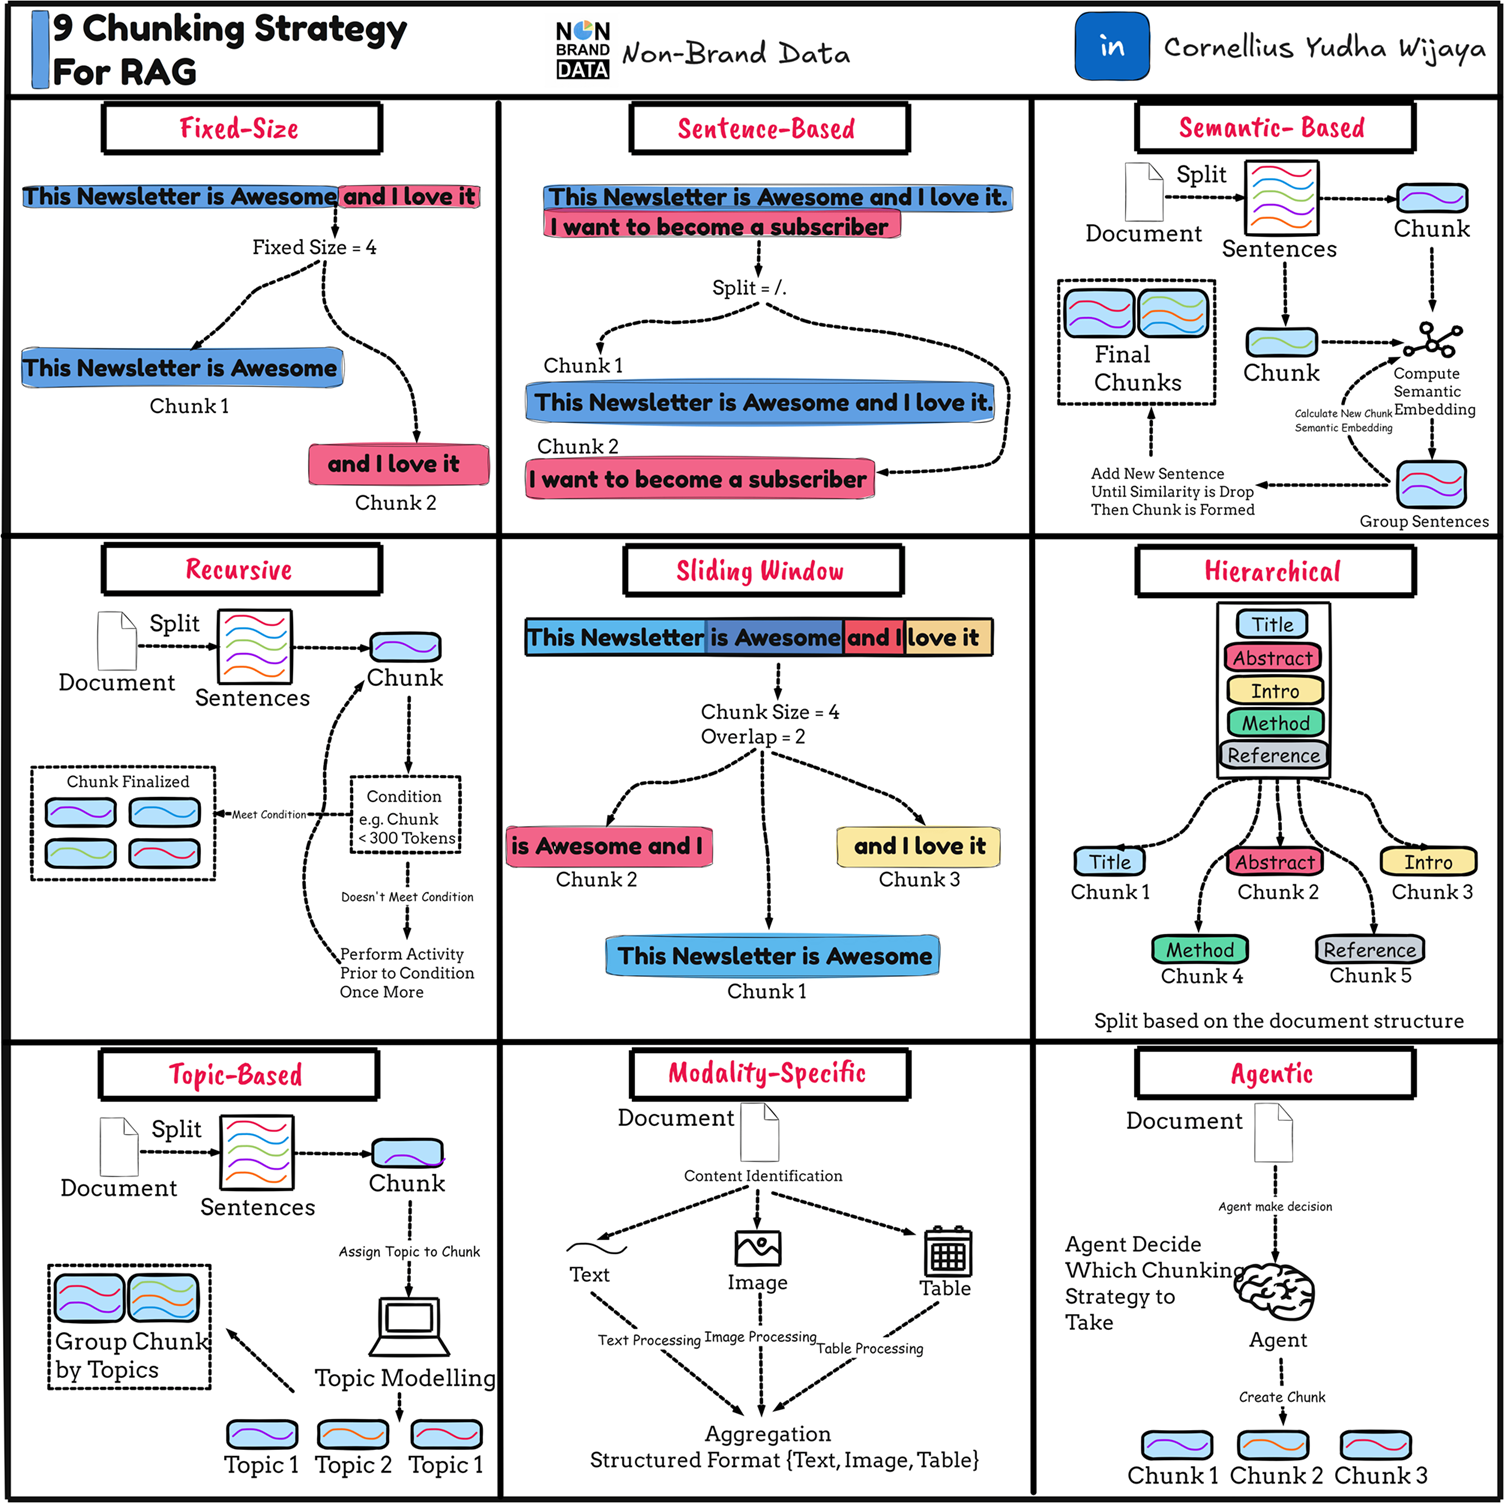

Source: [9 Chunking Strategies to Improve RAG Performance](https://www.nb-data.com/p/9-chunking-strategis-to-improve-rag)

#### Lets look at how Semantic Chunking work, applied to a very simple example. Here is our text:
```text
Sentence 1: Preheat your oven to 350 degrees before mixing the flour and sugar.
Sentence 2: Bake the cake for thirty minutes until golden brown.
Sentence 3: Solid-state drives use flash memory to achieve fast data transfer speeds.
Sentence 4: Installing a new GPU requires an available PCIe slot on the motherboard.
```
Now, we compute similarity between adjacent sentences:
```
Pair (1 & 2): Both discuss baking a cake. High similarity score --> 0.92.
Pair (2 & 3): Sentence 2 is about baking; Sentence 3 shifts to hardware. Low similarity score --> 0.17 (drops below threshold).
Pair (3 & 4): Both discuss computer components. High similarity score --> 0.85.
```
Two distinct chunks emerge:
```
Chunk 1: "Preheat your oven to 350 degrees before mixing the flour and sugar. Bake the cake for thirty minutes until golden brown."
Chunk 2: "Solid-state drives use flash memory to achieve fast data transfer speeds. Installing a new GPU requires an available PCIe slot on the motherboard."
```

> **Important:** As we'll see in the next section, the embedding model is limited in the number of tokens it can take ("Sequence Length") before truncating the input text. Unlike with LLMs, commonly used open-source embedding models can take between 256 and 784 input tokens (180 to 570 words, roughly). Do your best that your chunks comply with this limitation!

#### 👉 📺 [The 5 Levels Of Text Splitting For Retrieval - Greg Kamradt](https://www.youtube.com/watch?v=8OJC21T2SL4)

<hr/>

### 💥 Demo 2 - Extraction, Cleanup and Chunking using `LangChain` and `unstructured`.

<hr/>

### Embedding

*Embedding* is a vector representation of text that captures its semantic meaning in numerical space (usually 384 to 5120 dimensions). Embeddings are what makes it possible to assess similarity between a given user query and the corpus of chunked documents.

> 🤔 **How Sentence Embeddings Work?** Sentence embeddings are created by converting text into a fixed-length numerical vector that captures semantic meaning. The process typically uses a **Transformer Encoder** (like BERT) which breaks the sentence into tokens and utilizes **self-attention** to analyze them simultaneously. This allows the model to understand context—distinguishing, for example, whether "bank" refers to a river or money—before "pooling" (averaging) the resulting contextualized token embeddings into a single summary vector.
>
>Crucially, the model learns to organize these vectors effectively through **Contrastive Learning** (often using a Siamese Network structure). The training data consists of sentence pairs: **positive pairs** (sentences with similar meanings) and **negative pairs** (sentences with dissimilar meanings). The training objective is to adjust the model's weights so that the similarity score (typically **cosine similarity**) is maximized between positive pairs and minimized between negative pairs.
>
> This "push-pull" training ensures that the final vectors reflect actual semantic relationships, as illustrated by these examples:
>
>>**Positive Pair (Target: High Similarity Score)**<br/>
> *A:* *"How can I lose weight quickly?"*<br/>
> *B:* *"What are some fast ways to shed pounds?"*<br/>
> (The model pulls these vectors together because the intent is identical, even if words differ.)
>
>>**Negative Pair (Target: Low Similarity Score)**<br/>
> *A:* *"How can I lose weight quickly?"*<br/>
> *C:* *"How do I cook pasta al dente?"*<br/>
> (The model pushes these vectors apart because the topics are unrelated.)

🌀 Document embedding is actually sentence embedding in disguise. To embed a document, each of it's sentences is embedded individually, then a *pooling function* is applied to aggregate the sentence embedding vectors into one (commonly a *mean* function). And there you have one more reason why you should limit the size of your chunks...

> **Note:** The concept of embedding is not limited to textual data only. The concept can be applied to other types of data, like images and sounds. 

#### Choosing an Embedding Model

Not all embedding models are born equal. Here are the main criteria you should be considering before choosing a model:

<table><thead>
  <tr bgcolor="#BBDDBB" align= "left">
    <th>Consideration</th>
    <th>Description</th>
  </tr></thead>
<tbody>
  <tr>
    <td><b>Accuracy / Semantic Quality</b></td>
    <td>How well the vectors preserve meaning and enable relevant retrieval</td>
  </tr>
  <tr>
    <td><b>Latency / Speed</b></td>
    <td>Do you need real-time or batch processing?</td>
  </tr>
  <tr>
    <td><b>Embedding size</b></td>
    <td>Larger = better semantics, but slower + more memory</td>
  </tr>
  <tr>
    <td><b>Multilingual support</b></td>
    <td>Needed for non-English or multi-language corpora</td>
  </tr>
  <tr>
    <td><b>Open vs Proprietary</b></td>
    <td>Do you need on-premise? Cost-free?</td>
  </tr>
  <tr>
    <td><b>Alignment with LLM</b></td>
    <td>Matching embedding model family with your generation model may improve synergy</td>
  </tr>
  <tr>
    <td><b>License</b></td>
    <td>Open-source vs. commercial use limitations</td>
  </tr>
</tbody></table>

Some popular embedding models are (very partial list):

<table><thead>
  <tr bgcolor="#BBDDBB" align= "left">
    <th>Model</th>
    <th>Dimensions</th>
    <th>Context Length</th>
    <th>Type</th>
    <th>Pros</th>
    <th>Cons</th>
  </tr></thead>
<tbody>
  <tr>
    <td><b>text-embedding-ada-002</b> (OpenAI)</td>
    <td>1536</td>
    <td>8192</td>
    <td>Commercial</td>
    <td>Very high quality, context length</td>
    <td>API cost, no on-prem</td>
  </tr>
  <tr>
    <td><b>all-MiniLM-L6-v2</b></td>
    <td>384</td>
    <td>256</td>
    <td>Open-source</td>
    <td>Fast, decent quality, free</td>
    <td>Context length, lower semantic search scores</td>
  </tr>
  <tr>
    <td><b>all-mpnet-base-v2</b></td>
    <td>768</td>
    <td>384</td>
    <td>Open-source</td>
    <td>High quality, free</td>
    <td>Considerably slower than MiniLM</td>
  </tr>
  <tr>
    <td><b>nomic-embed-text-v1</b></td>
    <td>768</td>
    <td>8192</td>
    <td>Free to use</td>
    <td>High quality, context length</td>
    <td>Considerably slower than MiniLM</td>
  </tr>
  <tr>
    <td><b>bge-base-en-v1.5</b>(BAAI)</td>
    <td>1024</td>
    <td>512</td>
    <td>Open-source</td>
    <td>High quality, higher dim (compared to other open-source)</td>
    <td>Beijing Academy of AI (to whom it may concern)</td>
  </tr>
</tbody></table>

> **Hint:** For English-only solutions and small to medium setups, use `MiniLM` or, even better, `all-mpnet-base-v2` if embedding speed is less of a concern.

#### 👉 For additional information and quality scores see [Sentence Transformers' documentation on embedding models](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html#original-models).

> For multi-lingual models, ***including Hebrew!***: https://www.sbert.net/docs/sentence_transformer/pretrained_models.html#multilingual-models

#### Popular Embedding Tools and Libraries

* `transformers`: access to a large library of open-source / free models. Maximum control over handling the embedding vectors.
* `sentence-transformers`: like transformers, except that the post-processing is done for you and the API is nicer to use.
* `openai`: provides a Python SDK.
* `langchain.embeddings`: a wrapper for most embedding providers. Integrates well with other `langchain` components.
* `Vector Stores`: some integrate the embedding as part of adding or updating a document in the store. 

👉 And, finally, here is HuggingFace's [Embedding Leaderboard](https://huggingface.co/spaces/mteb/leaderboard).

<hr/>

### 💥 Demo 3 - Embedding using `transformers`, `sentence_transformers` and `LangChain`.

<hr/>

### Vector Store Ingestion

Now that we have our chunks and their embeddings, it's time to put it all into a *Vector Store*. As we've already seen in the "bear-bones" code example, *Vector Stores'* main purpose is to allow for semantic search based on document embedding vector similarity. But many (not all!) of the current offerings do more than just that - they allow for storing of the document alongside it's embedding vector, include per-document metadata, employ different searching strategies, and more.

In the next section we'll delve deeper into options those *Vector Stores* provide, and even name names. But, for now, let's see a quick demo.

<hr/>

### 💥 Demo 4 - Vector Store using `ChromaDB`.

<hr/>

# Section 3 - Retrieval Techniques

Given a user query, the *Vector Store* fetches the documents to be used for augmenting the query before it's passed to the LLM for generating a response. We'll discuss some of the more common retrieval approaches.

### Lexical vs. Semantic Search

There are two main retrieval approaches: ***Lexical*** and ***Semantic***. *Lexical Search* excels in speed and precision when dealing with specific terms or structured data, making it particularly useful when users know exactly what they're looking for. It offers efficiency in retrieving exact matches. In contrast, *Semantic Search* shines in handling natural language queries, understanding context, and exploring related concepts. While lexical search provides quick results, semantic search delivers depth, flexibility, and relevance by grasping the nuances of language and intent behind queries.

#### Lexical Search 

Usually uses either [👉`TF-IDF`](https://www.geeksforgeeks.org/understanding-tf-idf-term-frequency-inverse-document-frequency/) or [👉`BM25`](https://www.luigisbox.com/search-glossary/bm25/) algorithms to filter the documents most relevant to the keywords specified. This approach is similar to what "classic" document search engines like `Elasticsearch` and `Apache Solr` do.

#### Semantic Search

That is what Vector Stores excel at. We need some measure to determine how "closeness" is calculated between vectors (two documents, or a query and a document). These measures are, sometimes, referred to as **distance metrics** or **similarity metrics**. There are several such metrics in common use:

|Metric|Description|Use When|
|:-----|:----------|:-------|
**`Cosine Similarity`** | Measures angle between vectors | Most common for embeddings
**`Dot Product`** | Unnormalized inner product | If using unnormalized embeddings
**`Manhattan (L1)`** | Grid-line distance | Less common. When the data is sparse
**`Euclidean (L2)`** | Straight-line distance | For normalized vectors
**`Jaccard / Hamming`** | For binary or sparse data | Rare in dense embedding workflows

👉 A nice article on distance metrics and RAG [Evaluating Distance Metrics in RAG](https://medium.com/@amitnagal33/evaluating-distance-metrics-in-rag-a-comprehensive-analysis-of-embeddings-and-metrics-de42f8a5a395).

> **Important 1:** Not all distance metrics are supported by every **embedding model**. Make sure to look it up before deciding on one.

> **Important 2:** for some similarity metrics to work (like *Internal Product*), your document embedding vectors have to be normalized. If they are not, then similarity search will not work as expected. The `sentence_transformers` package does the work for you, same goes for `ollama`. Two simple options for normalizing your embedding vectors are:
>
> ```python
> # 1.
> normalized_embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
>
> # 2.
> normalized_embeddings = torch.nn.functional.normalize(embeddings, p=2, dim=1)
> ```

### Hybrid Search

Combines `TF-IDF` or `BM25` (Lexical) with vector similarity (Semantic).<br/>
Useful especially when the domain is technical or dense with keywords or jargon (like in the legal or medicine realms).   
Not all Vector Stores allow for Hybrid Search.

#### Reciprocal Rank Fusion (RRF)

When lexical and semantic retrievers are combined, their raw scores are usually not directly comparable: BM25 scores and vector distances have different meanings and ranges. **Reciprocal Rank Fusion (RRF)** avoids normalizing those scores. It combines the positions of a chunk in the ranked lists instead.

For ranked lists $R$, the fused score of chunk $d$ is:

$$
RRF(d) = \sum_{r \in R} \frac{1}{k + rank_r(d)}
$$

A chunk receives one contribution for every list in which it appears. Appearing near the top of both lists is rewarded, while a strong result found by only one retriever can still survive. The common value $k=60$ reduces the effect of small rank changes near the top; it is not the number of results to return.

In [ ]:
from collections import defaultdict


def reciprocal_rank_fusion(
    ranked_lists: list[list[str]],
    k: int = 60,
) -> list[tuple[str, float]]:
    # Each list contains document/chunk IDs ordered from best to worst.
    scores = defaultdict(float)

    for ranked_ids in ranked_lists:
        for rank, chunk_id in enumerate(ranked_ids, start=1):
            scores[chunk_id] += 1.0 / (k + rank)

    return sorted(scores.items(), key=lambda item: item[1], reverse=True)

In [ ]:
semantic_ranking = ["chunk-A", "chunk-B", "chunk-C"]
lexical_ranking = ["chunk-C", "chunk-A", "chunk-D"]

In [ ]:
reciprocal_rank_fusion([semantic_ranking, lexical_ranking])

In the example, `chunk-A` and `chunk-C` receive evidence from both retrievers. In a real pipeline, use stable chunk IDs for fusion, retain the full chunk dictionaries separately, and inspect the component ranks when debugging unexpected results.

### Metadata Filtering and Whole Document Search

Not to be confused with *Hybrid Search*, it allows for preliminary filtering of documents based on:
1. Metadata properties (tags, date range, access level, source, etc.), or
2. Keyword or phrase search within a document (like `Ctrl+F` search in a document). Also known as *Whole Document Search*.

Both filtering techniques can be combined.

> **Optional / Advanced**
>
> Active retrieval and MMR are useful follow-up techniques. In the core path, prioritize understanding lexical vs. semantic retrieval, metadata filtering, similarity thresholds, and reranking.


### Other Techniques

**Active Retrival**: The system dynamically decides: how many documents to retrieve, which retrieval method to use, and whether to re-query (feedback loop). [👉 Further reading](https://medium.com/etoai/better-rag-with-active-retrieval-augmented-generation-flare-3b66646e2a9f)

**Maximal Marginal Relevance (MMR)**: A technique designed to retrieve documents that are both *relevant* and *diverse*. [👉 Further reading](https://medium.com/@adergunov/maximal-marginal-relevance-144c23b42be5)

> **Reference**
>
> This comparison is useful for orientation, but do not spend core class time memorizing product matrices. The durable skill is choosing a store based on retrieval features, filtering needs, scale, operational constraints, and the surrounding application architecture.


### Top Vector Databases: Features & Comparisons

|Vector DB | Open Source? | Persistence | Filtering | Hybrid Support | Scalability |Similarity Search| Notes |
|:---------|:------------:|:-----------:|:---------:|:--------------:|:------------|:-----------------|:------|
**`FAISS`** | ✅ | ❌ (in-memory) | ❌ | ❌ | Medium | dot, L2 | Fast, low-level control, dump to file
**`ChromaDB`** | ✅ | ✅ | ✅ | ✅ | Dev / Small prod | dot, L2, cosine | Easy to use, good for POCs
**`Weaviate`** | ✅ | ✅ | ✅ | ✅ | Highly scalable | dot, L2, cosine, Manhattan | Strong hybrid & filter support
**`Qdrant`** | ✅ | ✅ | ✅ | ✅ | Scalable | dot, L2, cosine, Manhattan | Fast, production-ready
**`Milvus`** | ✅ | ✅ | ✅ | ✅ | Big Data scale | dot, L2, cosine | Requires more setup
**`Pinecone`** | ❌ | ✅ | ✅ | ✅ | Scalable | dot, L2, cosine | Fast, reliable, SaaS, paid
**`ElasticSearch`** | ✅ | ✅ | ✅ | ✅ | Highly scalable | dot, L2, cosine, Manhattan | Hybrid out of the box

#### 🤔 Which Vector Store to Choose?

Well...

➡️ *Need in-memory speed?* Use **`FAISS`**.<br/>
➡️ *Quick dev, PoC or small prod?* Use **`ChromaDB`**.<br/>
➡️ *Need hybrid retrieval?* Try **`Weaviate`**, **`Qdrant`**, or **`Pinecone`**.<br/>
➡️ *Enterprise-grade SaaS?* Use **`Pinecone`**.<br/>
➡️ *Have existing* **`Elasticsearch`** *infrastructure?* Consider adding vector fields to **`Elasticsearch`**.<br/>

> **BTW:** vector similarity search has even made its way to relational databases such as `Oracle` and `Postgresql`. Even AWS' `S3` service is in the game with *S3 Vectors*.

<hr/>

### 💥 Demo 5 - `ChromaDB` filtering & semantic search.

<hr/>

### Refining Search Results

#### Similarity Threshold

This one is pretty straightforward - how "close" to the query the retrieved documents need to be for them to be useful? In other words, what is the cut-off threshold for the similarity score? Documents with similarity score below the threshold are dropped (or above, as is the standard with Chroma). 

Simple as it may seem, figuring out the optimal threshold is not trivial.
* Values range depends on the distance metric you choose. And, if you change the distance metric sometime along the way, you have to update your threshold as well.
* What is "close enough"? This one is completely dependent on your needs and implementation. Some of the things to consider are:
    * Different embedding models give different similarity scores (on a given metric). Keep in mind that some models are fine-tuned on a specific task or domain.
    * How specific your response has to be? Does it have any margins for inaccuracies?
    * Do you have enough quality documents to answer the query or, maybe, information is sparse and something may be better than nothing?
    * Your embedding model's dimensionality (distance concentration problem 👉 [The Geometry of the Curse of Dimensionality: Why Distance Metrics Collapse...](https://medium.com/@sarthakpattanaik_4094/the-geometry-of-the-curse-of-dimensionality-why-distance-metrics-collapse-and-what-it-means-for-d3bcc2edfbdf)).

#### Reranking

*Reranking* refers to the process of reordering a set of initially retrieved documents based on their relevance to a user's query. During the vectorization of documents, there is substantial potential for semantic "signal" loss, as vectors represent documents in a compressed, high-dimensional, numerical format. The "signal" loss may yield less relevant or even irrelevant documents which, if fed to the LLM, would adversely affect the quality of generation. 

It may sound like more-of-the-same of what we have been doing with Semantic Search, but it takes a completely different approach to vector similarity. *Reranking* uses a **specialized language models** (not necessarily LLMs) to reassess the **semantic relevance** of the retrieved documents to a given query.

Think of it as a two-stage retrieval pipeline: *stage 1* we use semantic search or opt for a hybrid approach, then comes *stage 2* which, potentially, reorders the documents and, maybe, drops certain documents altogether (if it finds the relevance to be low).

There are several re-ranking techniques, like: `Cross-Encoders` (process the query and document together through a transformer architecture), `Multi-Vector Models` (represent documents as sets of contextualized token embeddings rather than single vectors), and `LLMs` (most powerful technique, but also the most computationally expensive).

👉 For more information: [Improve RAG with Re-ranking](https://medium.com/@ashpaklmulani/improve-retrieval-augmented-generation-rag-with-re-ranking-31799c670f8e).

> **Note:** we'll demonstrate Cross-Encoder re-ranking in the final demo.

# Section 4 - Context Injection & Prompt Design

Retrieval alone doesn't help unless we present the retrieved documents to the LLM effectively. Prompt construction is about:
* Formatting retrieved data as part of the prompt
* Giving the LLM clear instructions
* Reducing hallucinations and increasing relevance

### Generic Prompt Template

Instructional LLMs (like `Mistral`, `ChatGPT` and `Gemini`) accept prompts made up of these 4 elements:
* **System prompt**: set strict behavior (e.g., "You are an expert assistant specializing in ???").
* **Context block**: the retrieved docs.
* **Question / Request**: what it is that we want the LLM to do.
* **Instructions**: how to answer / comply (e.g., what to avoid, no hallucinations).

A question prompt template could look something like this:
```
You are an expert assistant in the field of <field of expertise>. Answer the user's question using ONLY the provided context.
Do not make up or hallucinate any part of the answer, base only on your given context.

If the context does not contain the answer, say "I don't know based on the context."

Context:
---
{context}
---

Question: {question}

Answer:
```

The `---` separates between the chunks, making it easier for the LLM to distinguish between them.

### Prompt Construction Strategies

#### ➡️ Stuffing (Concatenation)

This one is the simplest approach: concatenate all retrieved documents into a single prompt.

```
Answer the following question using ONLY the context provided.

Context:
[Document Chunk 1]
---
[Document Chunk 2]
---
[Document Chunk 3]
---

Question:
How do I reset my password?

Answer:
```

**Advantages**: 
* Simple to implement.
* Works with most LLMs.
* Great when the overall context is not too long.
* The fastest and most cost efficient strategy.

**Disadvantages**:
* Limited by LLM context window.
* Other strategies may yield better, more accurate answers.

✔️ **Best For**:
* Small document chunks.
* Few chunks per query.
* Low-latency Q&A
* Quick prototyping

#### ➡️ Map-Reduce

Run the question on **each chunk separately**, then **aggregate answers** to get the final answer.<br/>
"*Map*" step: LLM generates answers based on each chunk.<br/>
"*Reduce*" step: LLM combines all partial answers into one.

Flow in pseudo-Python:
```python
# Map
answers = [
    llm(prompt_with(chunk, question)) for chunk in docs
]
# Reduce
final_answer = llm("Summarize the following answers:\n" + "\n".join(answers))
```

**Advantages**: 
* Handles long docs and many chunks, chunk-by-chunk (see "variation" below).
* More focused context per answer.

**Disadvantages**:
* Single chunk may not provide enough context to generate quality answer, leading to an aggregation of low-quality answers.
* Slower (LLM call per chunk) and more expansive than *Stuffing*.

> **Variation:** To alleviate the disadvantages, it may be possible to divide the chunks into batches (several chunks each) per LLM call.

✔️ **Best For:**
* Long documents, or many chunks
* Summarization, synthesis, or opinionated answers (e.g. executive summary of multiple reports)

#### ➡️ Refine (Iterative Answer Improvement)

Starts with one chunk, generates an answer, then refines it with each new chunk.

Flow in pseudo-Python:
```python
# Initial chunk
answer = llm(prompt_with(chunks[0], user_query))
# Refine with each additional doc
for chunk in chunks[1:]:
    answer = llm(refine_prompt(answer, chunk, user_query))
```

The prompt template for the refinement stage (second chunk and onward) could look like this:

```
Here is a draft answer to a question, and a context.
Refine the answer using this context, if relevant.

Draft Answer:
{previous_answer}

New Context:
{chunk}

Question:
{question}
```

**Advantages**: 
* Handles long docs and many chunks (again, see "variation" below).
* Updating an answer ("refining") as new facts (chunks) come in, little by little, may yield better answers than trying to summarize a large number of answers - depending on the scenario. 

**Disadvantages**:
* The order in which the chunks are "presented" to the LLM may affect the final answer.
* Context loss (whether in the form of the actual chunks, or their summary).
* Cross-chunks reasoning may be weaker.

> **Variation:** To alleviate some of the disadvantages, it may be possible to divide the chunks into batches (several chunks each) per LLM call.

✔️ **Best For**:
* Maintaining continuity across chunks (possible when chunks are naturally ordered, e.g. time series or a story)
* Task is too complex for a single response
* Multi-hop reasoning (i.e. combine logical reasoning and knowledge integration)

> **Optional / Advanced**
>
> Multi-query fusion and self-ask can improve recall on difficult questions, but they also add model calls, latency, cost, and more failure points. Treat these as extensions after the basic retrieval-and-grounding pipeline is solid.


#### ➡️ RAG-Fusion / Multi-query Fusion

Run multiple reformulated versions of the query, retrieve separately, then merge the answers for the final answer. This would require a preliminary call to the LLM.

An example query and reforumlations:
```
Original query: "How can I reset my password?"

Reformulated versions of the original query:
- "What are the steps for password recovery?"
- "Where is the reset password option?"
```

To get the answer per reformulated question you can use any of the first three strategies we discussed, `Stuffing`, `Map-Reduce` or `Refine`.

Another variant is to use the reformulated questions for retrieving relevant documents for each. Then, deduplicate the documents and then use plain stuffing to get the final answer. This promotes high recall (fewer relevant documents left behind), and good for ambiguous or high-variance questions.

#### ➡️ Self-Ask

Use the LLM to **generate sub-queries** and **run retrieval for each**, combining them for a final answer. Like with `RAG-Fusion`, this would require a preliminary call to the LLM in order to "expand" the original query and derive sub-queries from it.

An example query and derived sub-queries could be:
```
Original query: "How do I cancel my subscription?"

Derived sub-queries:
1. "Where do I find the subscription settings?"
2. "What is the cancellation process?"
3. "What happens to my personal details after cancellation?"
```

For retrieval you can use any of the first three strategies we discussed, `Stuffing`, `Map-Reduce` or `Refine`.

<hr/>

### 💥 Demo 6 - Putting It All Together

<hr/>

### 🫵 Exercise: Debugging a RAG Failure

<hr/>

## Minimum Viable RAG Evaluation

You do not need a sophisticated evaluation platform to start comparing RAG versions. Before changing chunk size, embedding model, retrieval strategy, or prompt, create a small **golden set**.

A useful first version contains roughly **10-20 questions** and deliberately includes:

- normal answerable questions,
- questions where the answer appears in different document types,
- ambiguous questions,
- questions that require metadata filtering,
- questions that **should not be answered** from the available corpus.

For every case, record the **expected source** and the **expected system behavior**. Then inspect retrieval and generation separately.

A simple evaluation loop is:

1. Run the same golden cases against version A.
2. Record which chunks were retrieved.
3. Check whether the expected source appeared.
4. Check whether the final answer was grounded in the retrieved evidence.
5. Run the same cases against version B.
6. Compare the failures-not just the answers that "sound better."

> **Important**: A fluent answer is not evidence that the RAG pipeline is correct!

### Lightweight evaluation table

| Case ID | Question | Expected source | Expected behavior | Retrieved correct source? | Answer grounded? | Notes |
|---|---|---|---|---|---|---|
| G-01 |  |  | answer / refuse / clarify / escalate |  |  |  |
| G-02 |  |  |  |  |  |  |
| G-03 |  |  |  |  |  |  |

This is intentionally lightweight. A later course module will expand this idea into systematic evaluation sets, run records, traces, version comparison, and application-level observability.

<hr/>

### 🫵 Exercise: Threat Assessment

<hr/>

# Section 5 - Appendix

### More on Evaluating Retrieval Quality

Out of scope but, in case you are interested (and you should be!), here is a **great** page expanding on the subject:

#### 👉 [Best Practices in RAG Evaluation: A Comprehensive Guide](https://qdrant.tech/blog/rag-evaluation-guide/)

### Additional Techniques

#### Optional / Advanced - Text-to-SQL

Converts natural language questions or requests into SQL queries that can be executed on a structured database. This is often used as part of a broader RAG pipeline where structured data (e.g., from SQL databases) is one of the retrieval sources (alongside documents and other sources).

This capability is extremely useful when we want to inject up-to-date information stored in an SQL database to our answers. Think about being able to answer questions like "What was the top-selling product last quarter?" **without hard-coding queries**!

To accomplish `Text-to-SQL` we need:
1. LLM fine-tuned on text-to-sql tasks (e.g. Defog's `SQLCoder` model)
2. Our database schema in the form of DDL statements
3. Special prompt format (depending on the model used)

<hr/>

### 💥 Demo 7 - Text-to-SQL using `transformers`

<hr/>

## [Optional] 😎 Similarity Search for Images

<hr/>

# From RAG to Applications

You should now understand both **how to build a RAG pipeline** and **how to diagnose where it can fail**.

### You should now understand

- how ingestion and cleanup affect everything downstream,
- chunking tradeoffs,
- embeddings and vector-store retrieval,
- lexical vs. semantic retrieval,
- metadata filtering, thresholds, and reranking,
- how retrieved context is injected into prompts,
- why grounded answers and source awareness matter,
- why RAG failures must be diagnosed stage by stage.

### You should now be able to

- build a basic document-to-answer RAG pipeline,
- compare retrieval strategies,
- inspect retrieved evidence,
- create a small golden evaluation set,
- distinguish retrieval failures from generation failures,
- choose a safe fallback when the corpus does not support an answer.


The next modules add **agents and workflow design**. Later, you will return to RAG from an application-engineering perspective: exposing it behind application boundaries, recording runs and traces, evaluating versions systematically, and deploying it as part of a reliable AI service.

<hr/>

<center>
    <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/e/ea/Thats_all_folks.svg/1280px-Thats_all_folks.svg.png" />
</center>